# 20 — Rainfall scenario comparison lab

This notebook creates a small SWMM model with several subcatchments, then runs the same drainage system under different rainfall events: **2-year**, **30-year**, and **100-year** synthetic design storms, each with and without climate-change uplift factors.

The goal is to demonstrate a clean scenario workflow: build one base model, modify only the rainfall event, run each scenario, and compare runoff hydrographs and summary metrics with plots.


## What this notebook demonstrates

- Build a sample SWMM model programmatically.
- Create synthetic design hyetographs for multiple return periods.
- Apply climate-change rainfall multipliers.
- Run each rainfall scenario independently.
- Compare total runoff hydrographs, peak runoff, runoff volume index, and subcatchment responses.
- Save scenario input files for review.

> **Important engineering note:** The rainfall depths in this notebook are illustrative teaching values, not official IDF data. For real projects, replace them with the local authority/NOAA/Atlas/FEH/IDF rainfall data appropriate for your location and design standard.


In [1]:
from pathlib import Path
import re
import sys
import warnings

# Prefer the local repository source when this notebook is run from the repo root
# or from the examples folder. This avoids accidentally using an older installed
# swmmx wheel while developing/testing new functionality.
_here = Path.cwd().resolve()
for _candidate in (_here / "src", _here.parent / "src"):
    if (_candidate / "swmmx").exists() and str(_candidate) not in sys.path:
        sys.path.insert(0, str(_candidate))
        break

import matplotlib.pyplot as plt
import pandas as pd

import swmmx
from swmmx import swmm

print(f"Using swmmx {swmmx.__version__} from {Path(swmmx.__file__).resolve()}")

OUTPUT_DIR = Path("output/rainfall_scenario_lab")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

warnings.filterwarnings("ignore", category=UserWarning)
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.grid"] = True


Using swmmx 0.0.43 from C:\Users\Mohammadali\Documents\My_Codes\swmmx_dev\src\swmmx\__init__.py


## Define rainfall events

The scenarios use a 6-hour synthetic storm at 5-minute resolution. The event shape is a simple dimensionless hyetograph with the highest intensity near the middle of the storm. Each return period controls the total rainfall depth, and each climate scenario multiplies that depth.

You can replace `BASE_DEPTHS_MM` with your project IDF depths, or replace `design_hyetograph()` entirely with your own temporal distribution.


In [2]:
START = pd.Timestamp("2000-01-01 00:00")
DURATION_HOURS = 6
STEP_MINUTES = 5

# Illustrative total rainfall depths for a 6-hour event.
# Replace these with official local IDF/design-storm depths for real work.
BASE_DEPTHS_MM = {
    "2-year": 45.0,
    "30-year": 85.0,
    "100-year": 115.0,
}

CLIMATE_FACTORS = {
    "current climate": 1.00,
    "climate +10%": 1.10,
    "climate +20%": 1.20,
}


def design_hyetograph(total_depth_mm, *, start=START, duration_hours=DURATION_HOURS, step_minutes=STEP_MINUTES):
    """Return a 5-minute design hyetograph as rainfall intensity in mm/hr."""

    periods = int(duration_hours * 60 / step_minutes) + 1
    times = pd.date_range(start, periods=periods, freq=f"{step_minutes}min")

    # A compact synthetic temporal pattern: light beginning/end, intense middle.
    # Values are dimensionless weights; they are normalized to total_depth_mm.
    weights = []
    for i in range(periods):
        fraction = i / (periods - 1)
        if fraction < 0.18:
            weight = 0.15
        elif fraction < 0.35:
            weight = 0.75
        elif fraction < 0.50:
            weight = 1.80
        elif fraction < 0.62:
            weight = 3.20
        elif fraction < 0.75:
            weight = 1.25
        elif fraction < 0.90:
            weight = 0.45
        else:
            weight = 0.12
        weights.append(weight)

    weights = pd.Series(weights, index=times, dtype=float)
    interval_depth_mm = weights / weights.sum() * total_depth_mm
    intensity_mm_per_hr = interval_depth_mm / (step_minutes / 60)
    return intensity_mm_per_hr.rename("rainfall_intensity_mm_hr")


def swmm_time_series_rows(intensity):
    """Convert a pandas Series to SWMM time-series rows."""

    return [(time.strftime("%m/%d/%Y %H:%M"), float(value)) for time, value in intensity.items()]


def scenario_name(return_period, climate_label):
    return f"{return_period} — {climate_label}"


def slugify(text):
    return re.sub(r"[^a-z0-9]+", "_", text.lower()).strip("_")


In [3]:
rainfall_scenarios = []
for return_period, base_depth in BASE_DEPTHS_MM.items():
    for climate_label, factor in CLIMATE_FACTORS.items():
        depth = base_depth * factor
        rainfall_scenarios.append(
            {
                "name": scenario_name(return_period, climate_label),
                "return_period": return_period,
                "climate": climate_label,
                "factor": factor,
                "depth_mm": depth,
                "rainfall": design_hyetograph(depth),
            }
        )

rainfall_summary = pd.DataFrame(
    [
        {
            "scenario": s["name"],
            "return_period": s["return_period"],
            "climate": s["climate"],
            "climate_factor": s["factor"],
            "total_depth_mm": s["depth_mm"],
            "peak_intensity_mm_hr": s["rainfall"].max(),
        }
        for s in rainfall_scenarios
    ]
).set_index("scenario")

rainfall_summary.round(2)


,return_period,climate,climate_factor,total_depth_mm,peak_intensity_mm_hr
scenario,,,,,
2-year — current climate,2-year,current climate,1.0,45.0,22.84
2-year — climate +10%,2-year,climate +10%,1.1,49.5,25.12
2-year — climate +20%,2-year,climate +20%,1.2,54.0,27.41
30-year — current climate,30-year,current climate,1.0,85.0,43.14
30-year — climate +10%,30-year,climate +10%,1.1,93.5,47.45
30-year — climate +20%,30-year,climate +20%,1.2,102.0,51.77
100-year — current climate,100-year,current climate,1.0,115.0,58.37
100-year — climate +10%,100-year,climate +10%,1.1,126.5,64.20
100-year — climate +20%,100-year,climate +20%,1.2,138.0,70.04


## Plot the rainfall events

This plot shows the generated rainfall intensity time series. The 30-year and 100-year storms have larger total depth and higher peak intensity; the climate uplift scenarios multiply the same storm shape.


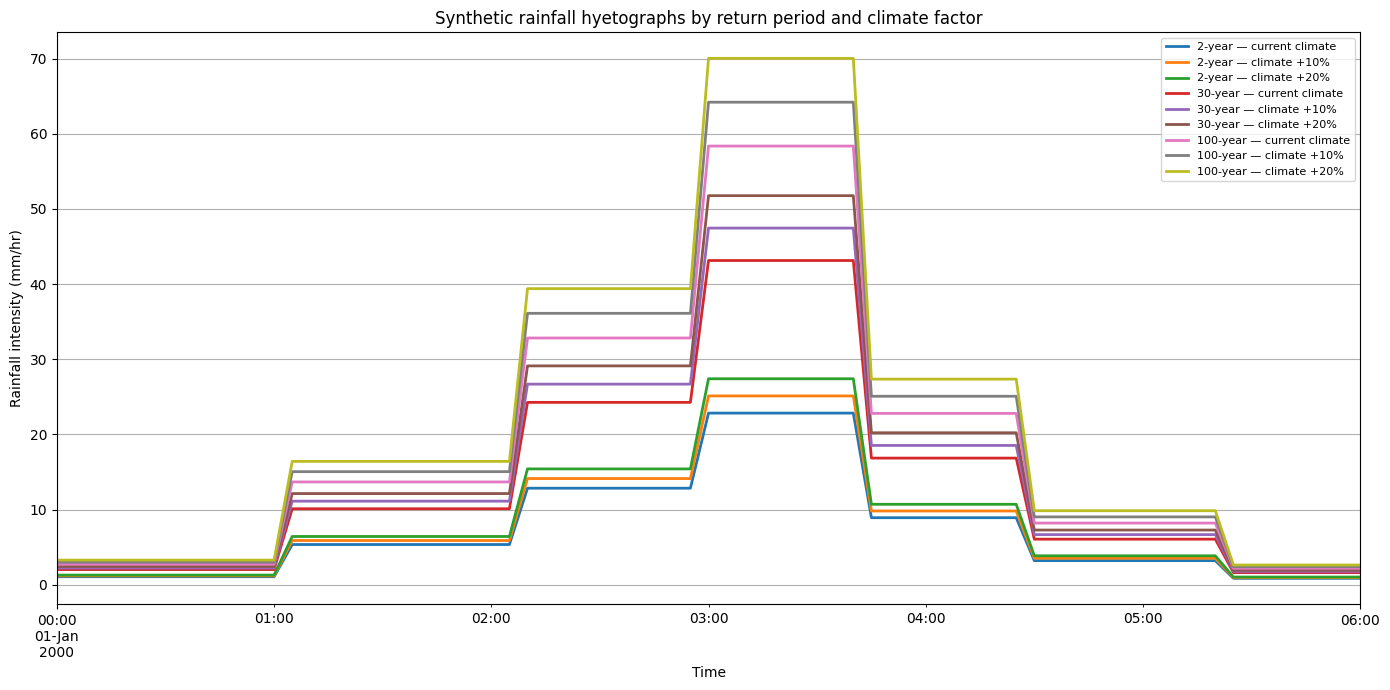

In [4]:
rainfall_frame = pd.concat([s["rainfall"].rename(s["name"]) for s in rainfall_scenarios], axis=1)

ax = rainfall_frame.plot(figsize=(14, 7), linewidth=2)
ax.set_title("Synthetic rainfall hyetographs by return period and climate factor")
ax.set_xlabel("Time")
ax.set_ylabel("Rainfall intensity (mm/hr)")
ax.legend(loc="upper right", fontsize=8)
plt.tight_layout()


## Build the base SWMM model

Each scenario uses the same drainage system: five subcatchments drain to five junctions and then to one outfall. The only difference between scenarios is the rainfall time series assigned to the rain gage.


In [5]:
def build_model_for_rainfall(rainfall, *, rainfall_id="ScenarioRain"):
    """Create a runnable SWMM model using one supplied rainfall hyetograph."""

    m = swmm(new="SI")
    options = {
        "FLOW_UNITS": "CMS",
        "INFILTRATION": "HORTON",
        "FLOW_ROUTING": "KINWAVE",
        "START_DATE": START.strftime("%m/%d/%Y"),
        "START_TIME": START.strftime("%H:%M:%S"),
        "END_DATE": (START + pd.Timedelta(hours=DURATION_HOURS)).strftime("%m/%d/%Y"),
        "END_TIME": (START + pd.Timedelta(hours=DURATION_HOURS)).strftime("%H:%M:%S"),
        "REPORT_START_DATE": START.strftime("%m/%d/%Y"),
        "REPORT_START_TIME": START.strftime("%H:%M:%S"),
        "REPORT_STEP": "00:05:00",
        "WET_STEP": "00:05:00",
        "DRY_STEP": "00:05:00",
        "ROUTING_STEP": "00:01:00",
    }
    for key, value in options.items():
        m.options[key] = value

    m.add.time.time_series(rainfall_id, data=swmm_time_series_rows(rainfall))
    m.add.hydrology.rain_gage(
        "RG1",
        format="INTENSITY",
        interval="00:05",
        source_type="TIMESERIES",
        time_series=rainfall_id,
        x=-40,
        y=120,
    )

    for i in range(1, 6):
        m.add.node.junction(
            f"J{i}",
            x=i * 100,
            y=0,
            invert_elevation=10 - i * 0.20,
            max_depth=4.0,
        )
    m.add.node.outfall("OUT1", x=650, y=0, invert_elevation=8.0, type="FREE")

    for i in range(1, 5):
        m.add.link.conduit(
            f"C{i}",
            from_node=f"J{i}",
            to_node=f"J{i+1}",
            roughness=0.013,
            shape="CIRCULAR",
            diameter=1.20,
        )
    m.add.link.conduit("C5", from_node="J5", to_node="OUT1", roughness=0.013, shape="CIRCULAR", diameter=1.20)

    subcatchments = [
        ("S1", "J1", 1.2, 100, 1.0, 45),
        ("S2", "J2", 1.4, 110, 1.2, 52),
        ("S3", "J3", 1.6, 120, 1.0, 60),
        ("S4", "J4", 1.8, 130, 0.9, 68),
        ("S5", "J5", 2.0, 140, 0.8, 72),
    ]
    for index, (sid, outlet, area, width, slope, impervious) in enumerate(subcatchments, start=1):
        x = index * 100
        y = 110
        polygon = [(x - 38, y - 28), (x + 38, y - 28), (x + 38, y + 28), (x - 38, y + 28)]
        m.add.hydrology.subcatchment(
            sid,
            rain_gage="RG1",
            outlet=outlet,
            x=x,
            y=y,
            area=area,
            width=width,
            slope=slope,
            impervious_percent=impervious,
            n_impervious=0.012,
            n_pervious=0.24,
            depression_storage_impervious=1.5,
            depression_storage_pervious=5.0,
            zero_depression_storage_impervious_percent=25,
            subarea_routing="OUTLET",
            percent_routed=100,
            maximum_rate=75,
            minimum_rate=3,
            decay=4,
            dry_time=7,
            maximum_volume=0,
            polygon=polygon,
        )
    return m


(<Figure size 3000x2400 with 1 Axes>, <Axes: >)

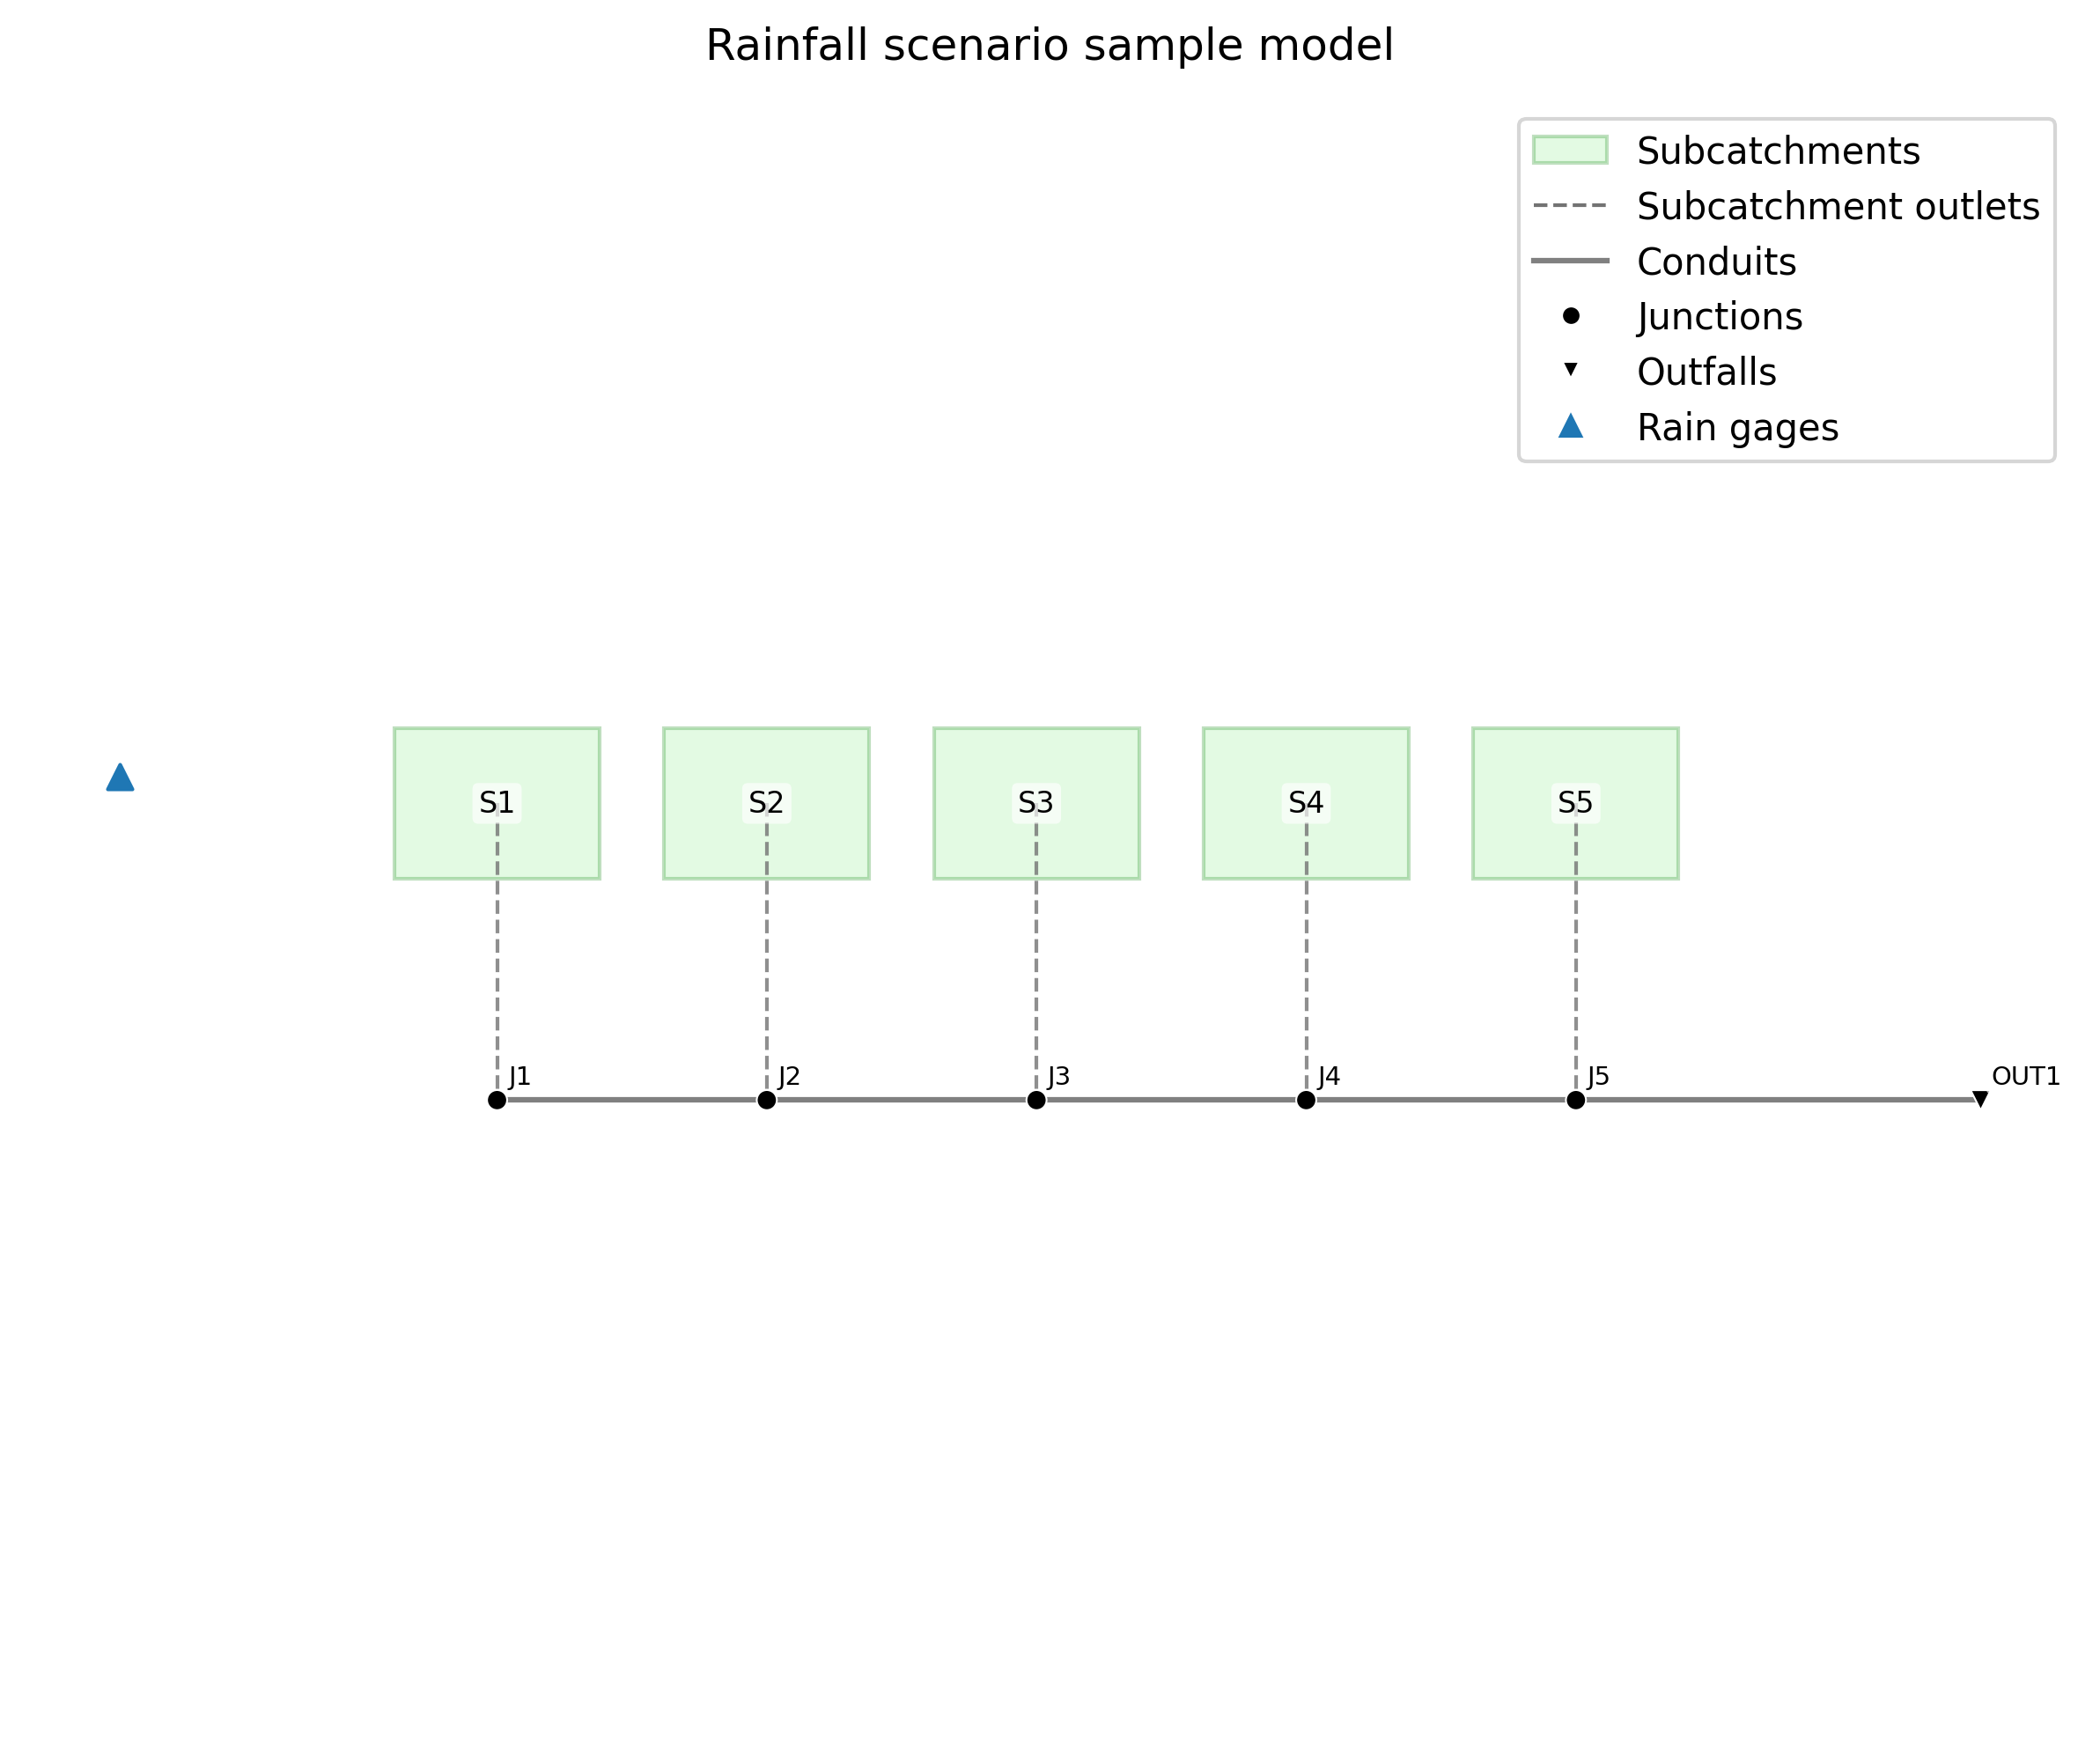

In [6]:
preview_model = build_model_for_rainfall(rainfall_scenarios[0]["rainfall"])
preview_model.plot_layout(
    title="Rainfall scenario sample model",
    annotation={
        "subcatchments": {"template": "{id}", "fontsize": 8, "bbox": True},
        "nodes": {"template": "{id}", "fontsize": 7, "bbox": True},
    },
)


## Run all rainfall scenarios

The `run_scenario()` function creates a fresh model for each rainfall event. This keeps the comparison clean: the network, subcatchment parameters, routing options, and reporting interval stay fixed.


In [7]:
def collect_metrics(scenario, model):
    runoff = model.get.subcatchment.runoff(format="df")
    node_depth = model.get.node.depth(format="df")
    link_flow = model.get.link.flow(format="df")

    total_hydrograph = runoff.sum(axis=1).rename(scenario["name"])
    return {
        "name": scenario["name"],
        "return_period": scenario["return_period"],
        "climate": scenario["climate"],
        "factor": scenario["factor"],
        "depth_mm": scenario["depth_mm"],
        "rainfall": scenario["rainfall"],
        "model": model,
        "runoff": runoff,
        "node_depth": node_depth,
        "link_flow": link_flow,
        "total_hydrograph": total_hydrograph,
        "total_runoff_index_sum": float(total_hydrograph.sum()),
        "peak_total_runoff": float(total_hydrograph.max()),
        "peak_node_depth": float(node_depth.max().max()),
        "peak_link_flow": float(link_flow.max().max()),
    }


def run_scenario(scenario, *, save_inp=True):
    print(f"Running: {scenario['name']}")
    model = build_model_for_rainfall(scenario["rainfall"])
    validation = model.validate()
    if not validation.ok:
        print(validation.to_frame())
    result = model.run()
    if not result.success:
        print(model.log())
        raise RuntimeError(f"Scenario failed: {scenario['name']}")
    if save_inp:
        model.save(OUTPUT_DIR / f"{slugify(scenario['name'])}.inp")
    return collect_metrics(scenario, model)


In [8]:
results = [run_scenario(scenario) for scenario in rainfall_scenarios]
print("Done.")


Running: 2-year — current climate
Running: 2-year — climate +10%
Running: 2-year — climate +20%
Running: 30-year — current climate
Running: 30-year — climate +10%
Running: 30-year — climate +20%
Running: 100-year — current climate
Running: 100-year — climate +10%
Running: 100-year — climate +20%
Done.


## Scenario metrics

The table below compares rainfall depth, total runoff index, peak total runoff, maximum node depth, and maximum link flow for each rainfall scenario.


In [9]:
metrics = pd.DataFrame(
    [
        {
            "scenario": r["name"],
            "return_period": r["return_period"],
            "climate": r["climate"],
            "rainfall_depth_mm": r["depth_mm"],
            "total_runoff_index_sum": r["total_runoff_index_sum"],
            "peak_total_runoff": r["peak_total_runoff"],
            "peak_node_depth": r["peak_node_depth"],
            "peak_link_flow": r["peak_link_flow"],
        }
        for r in results
    ]
).set_index("scenario")

metrics.round(3)


,return_period,climate,rainfall_depth_mm,total_runoff_index_sum,peak_total_runoff,peak_node_depth,peak_link_flow
scenario,,,,,,,
2-year — current climate,2-year,current climate,45.0,8.105,0.370,0.313,0.355
2-year — climate +10%,2-year,climate +10%,49.5,9.233,0.432,0.340,0.416
2-year — climate +20%,2-year,climate +20%,54.0,10.373,0.494,0.365,0.476
30-year — current climate,30-year,current climate,85.0,18.380,0.893,0.511,0.883
30-year — climate +10%,30-year,climate +10%,93.5,20.597,0.995,0.544,0.986
30-year — climate +20%,30-year,climate +20%,102.0,22.813,1.095,0.575,1.087
100-year — current climate,100-year,current climate,115.0,26.193,1.246,0.622,1.239
100-year — climate +10%,100-year,climate +10%,126.5,29.190,1.379,0.662,1.372
100-year — climate +20%,100-year,climate +20%,138.0,32.197,1.511,0.702,1.505


## Total runoff hydrographs

This plot compares the total runoff response across all subcatchments. The larger return periods and climate multipliers should produce higher and broader runoff hydrographs.


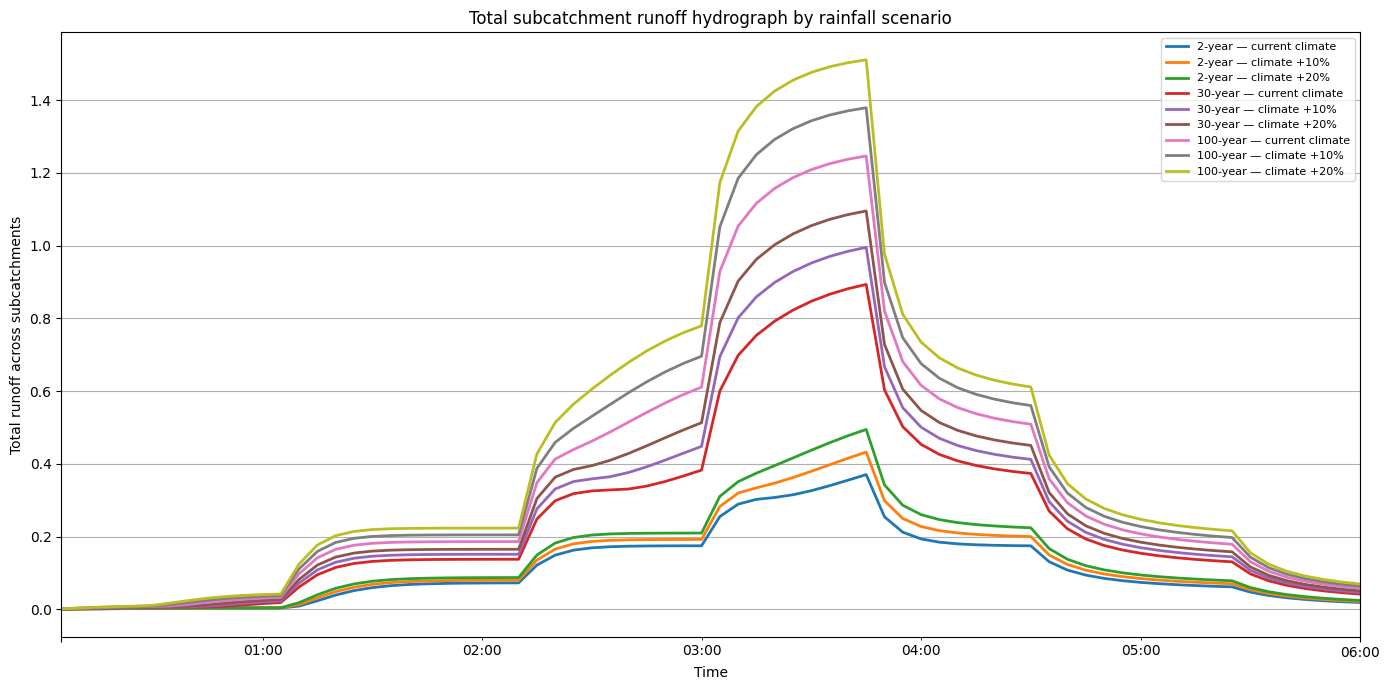

In [10]:
hydrographs = pd.concat([r["total_hydrograph"] for r in results], axis=1)

ax = hydrographs.plot(figsize=(14, 7), linewidth=2)
ax.set_title("Total subcatchment runoff hydrograph by rainfall scenario")
ax.set_xlabel("Time")
ax.set_ylabel("Total runoff across subcatchments")
ax.legend(loc="upper right", fontsize=8)
plt.tight_layout()


## Peak and total runoff comparison

The next two plots summarize the main hydrologic impact of each design storm. The total runoff index is the sum of the total runoff hydrograph over reporting steps; it is a convenient relative comparison inside this notebook, not a substitute for a formal volume calculation with units.


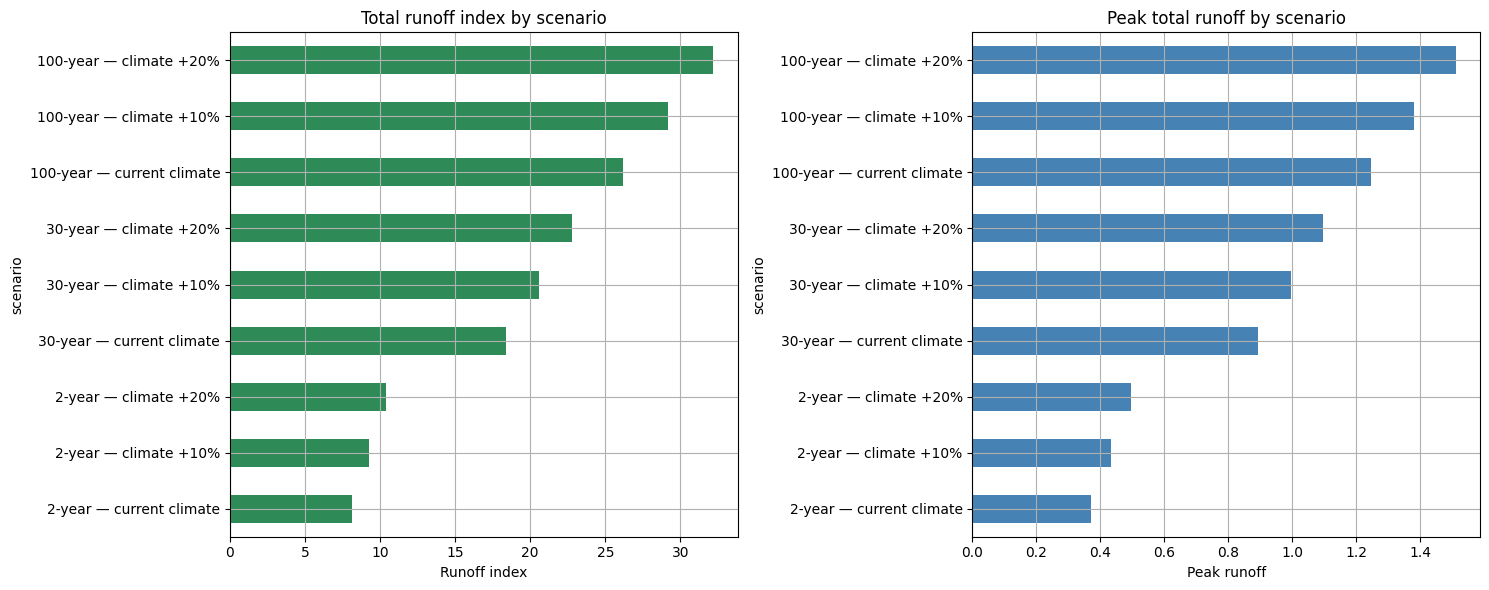

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

metrics["total_runoff_index_sum"].sort_values().plot(kind="barh", ax=axes[0], color="seagreen")
axes[0].set_title("Total runoff index by scenario")
axes[0].set_xlabel("Runoff index")

metrics["peak_total_runoff"].sort_values().plot(kind="barh", ax=axes[1], color="steelblue")
axes[1].set_title("Peak total runoff by scenario")
axes[1].set_xlabel("Peak runoff")
plt.tight_layout()


## Climate-change uplift within each return period

This view isolates the effect of climate multipliers. For each return period, the current-climate event is the reference case, and the +10% / +20% cases are compared against it.


In [12]:
climate_effect_rows = []
for return_period in BASE_DEPTHS_MM:
    group = metrics[metrics["return_period"] == return_period]
    base_name = scenario_name(return_period, "current climate")
    base_total = group.loc[base_name, "total_runoff_index_sum"]
    base_peak = group.loc[base_name, "peak_total_runoff"]
    for scenario, row in group.iterrows():
        climate_effect_rows.append(
            {
                "scenario": scenario,
                "return_period": return_period,
                "climate": row["climate"],
                "total_runoff_change_%": (row["total_runoff_index_sum"] - base_total) / base_total * 100,
                "peak_runoff_change_%": (row["peak_total_runoff"] - base_peak) / base_peak * 100,
            }
        )

climate_effect = pd.DataFrame(climate_effect_rows).set_index("scenario")
climate_effect.round(2)


,return_period,climate,total_runoff_change_%,peak_runoff_change_%
scenario,,,,
2-year — current climate,2-year,current climate,0.00,0.00
2-year — climate +10%,2-year,climate +10%,13.91,16.75
2-year — climate +20%,2-year,climate +20%,27.98,33.56
30-year — current climate,30-year,current climate,0.00,0.00
30-year — climate +10%,30-year,climate +10%,12.06,11.39
30-year — climate +20%,30-year,climate +20%,24.12,22.60
100-year — current climate,100-year,current climate,0.00,0.00
100-year — climate +10%,100-year,climate +10%,11.44,10.64
100-year — climate +20%,100-year,climate +20%,22.92,21.21


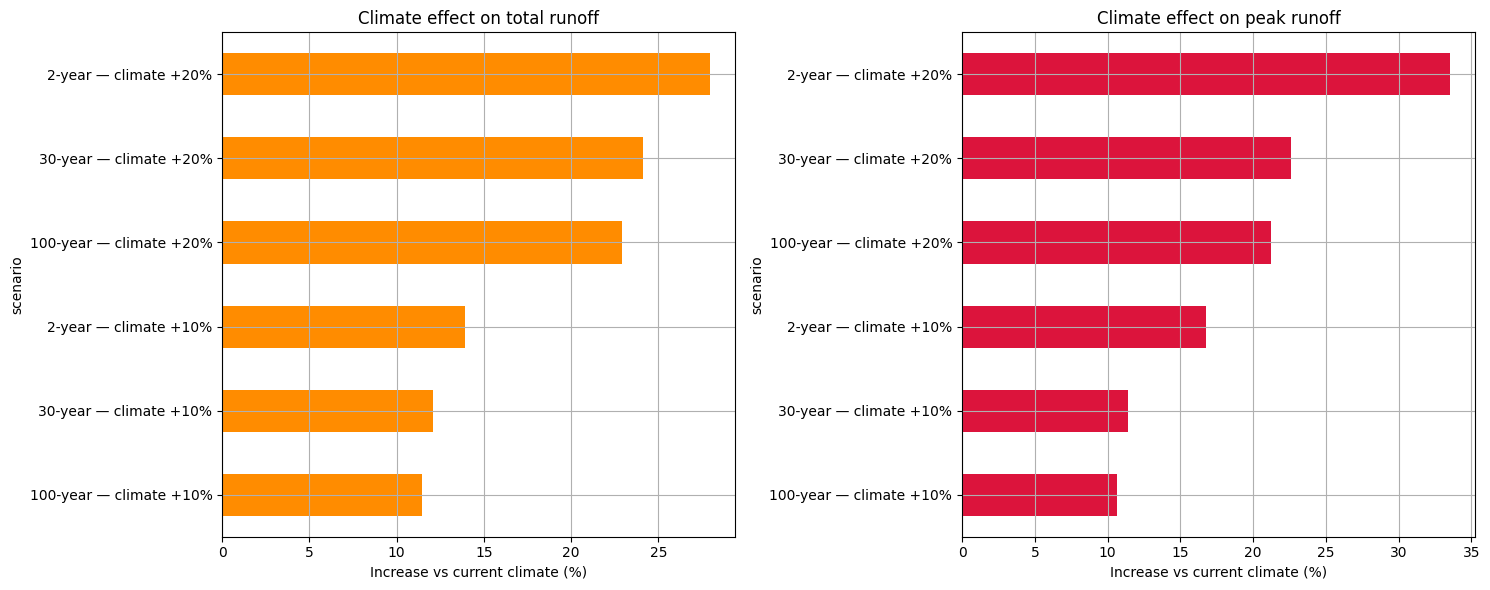

In [13]:
plot_frame = climate_effect[climate_effect["climate"] != "current climate"].copy()

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
plot_frame["total_runoff_change_%"].sort_values().plot(kind="barh", ax=axes[0], color="darkorange")
axes[0].set_title("Climate effect on total runoff")
axes[0].set_xlabel("Increase vs current climate (%)")

plot_frame["peak_runoff_change_%"].sort_values().plot(kind="barh", ax=axes[1], color="crimson")
axes[1].set_title("Climate effect on peak runoff")
axes[1].set_xlabel("Increase vs current climate (%)")
plt.tight_layout()


## Compare return periods under current climate only

This plot strips away the climate multipliers and compares the base 2-year, 30-year, and 100-year design storms.


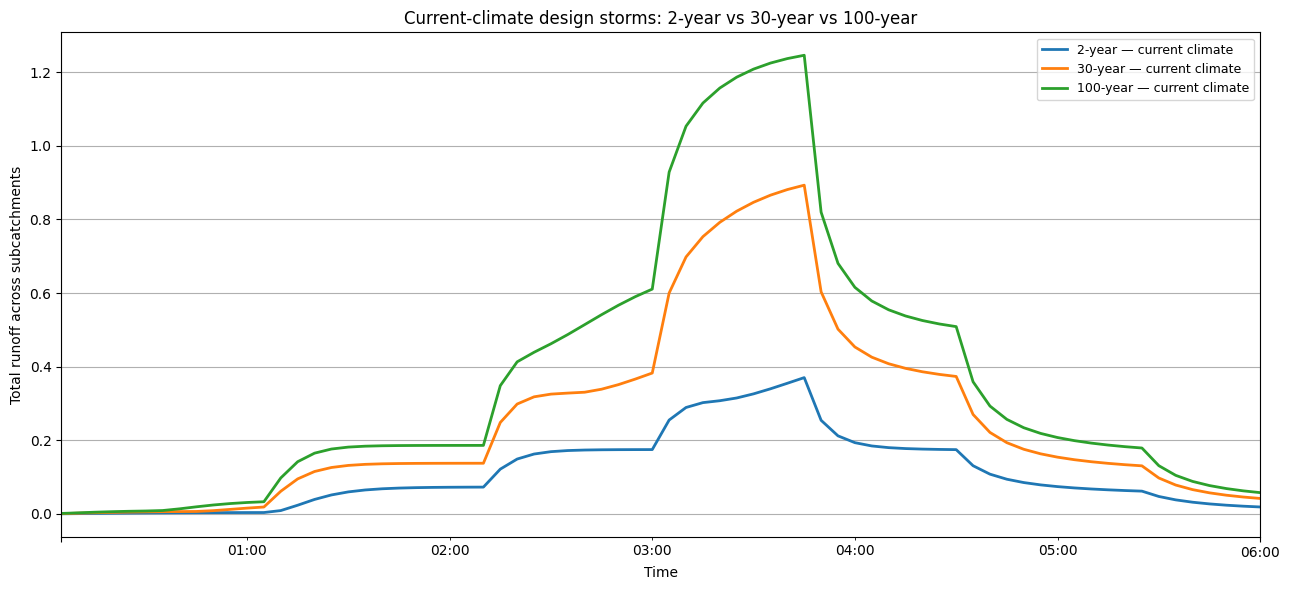

In [14]:
current_names = [scenario_name(rp, "current climate") for rp in BASE_DEPTHS_MM]
current_hydrographs = hydrographs[current_names]

ax = current_hydrographs.plot(figsize=(13, 6), linewidth=2)
ax.set_title("Current-climate design storms: 2-year vs 30-year vs 100-year")
ax.set_xlabel("Time")
ax.set_ylabel("Total runoff across subcatchments")
ax.legend(loc="upper right", fontsize=9)
plt.tight_layout()


## Subcatchment-level response

The heatmap below shows each subcatchment's peak runoff under each rainfall scenario. It helps identify which catchments dominate the system response as storm severity increases.


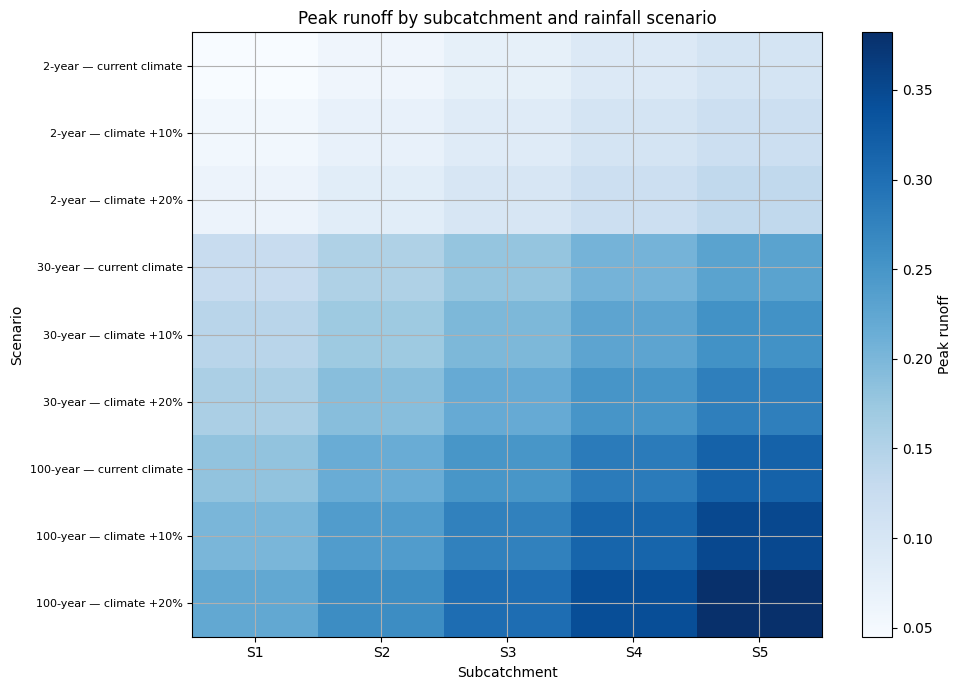

In [15]:
subcatchment_peak = pd.DataFrame({r["name"]: r["runoff"].max() for r in results}).T

fig, ax = plt.subplots(figsize=(10, 7))
image = ax.imshow(subcatchment_peak.values, aspect="auto", cmap="Blues")
ax.set_title("Peak runoff by subcatchment and rainfall scenario")
ax.set_xlabel("Subcatchment")
ax.set_ylabel("Scenario")
ax.set_xticks(range(len(subcatchment_peak.columns)))
ax.set_xticklabels(subcatchment_peak.columns)
ax.set_yticks(range(len(subcatchment_peak.index)))
ax.set_yticklabels(subcatchment_peak.index, fontsize=8)
fig.colorbar(image, ax=ax, label="Peak runoff")
plt.tight_layout()


## Inspect one severe scenario layout

Because every scenario returns its model object, you can inspect the network, results, and plots for any scenario. Here we display the 100-year event with the +20% climate multiplier.


(<Figure size 3000x2400 with 1 Axes>, <Axes: >)

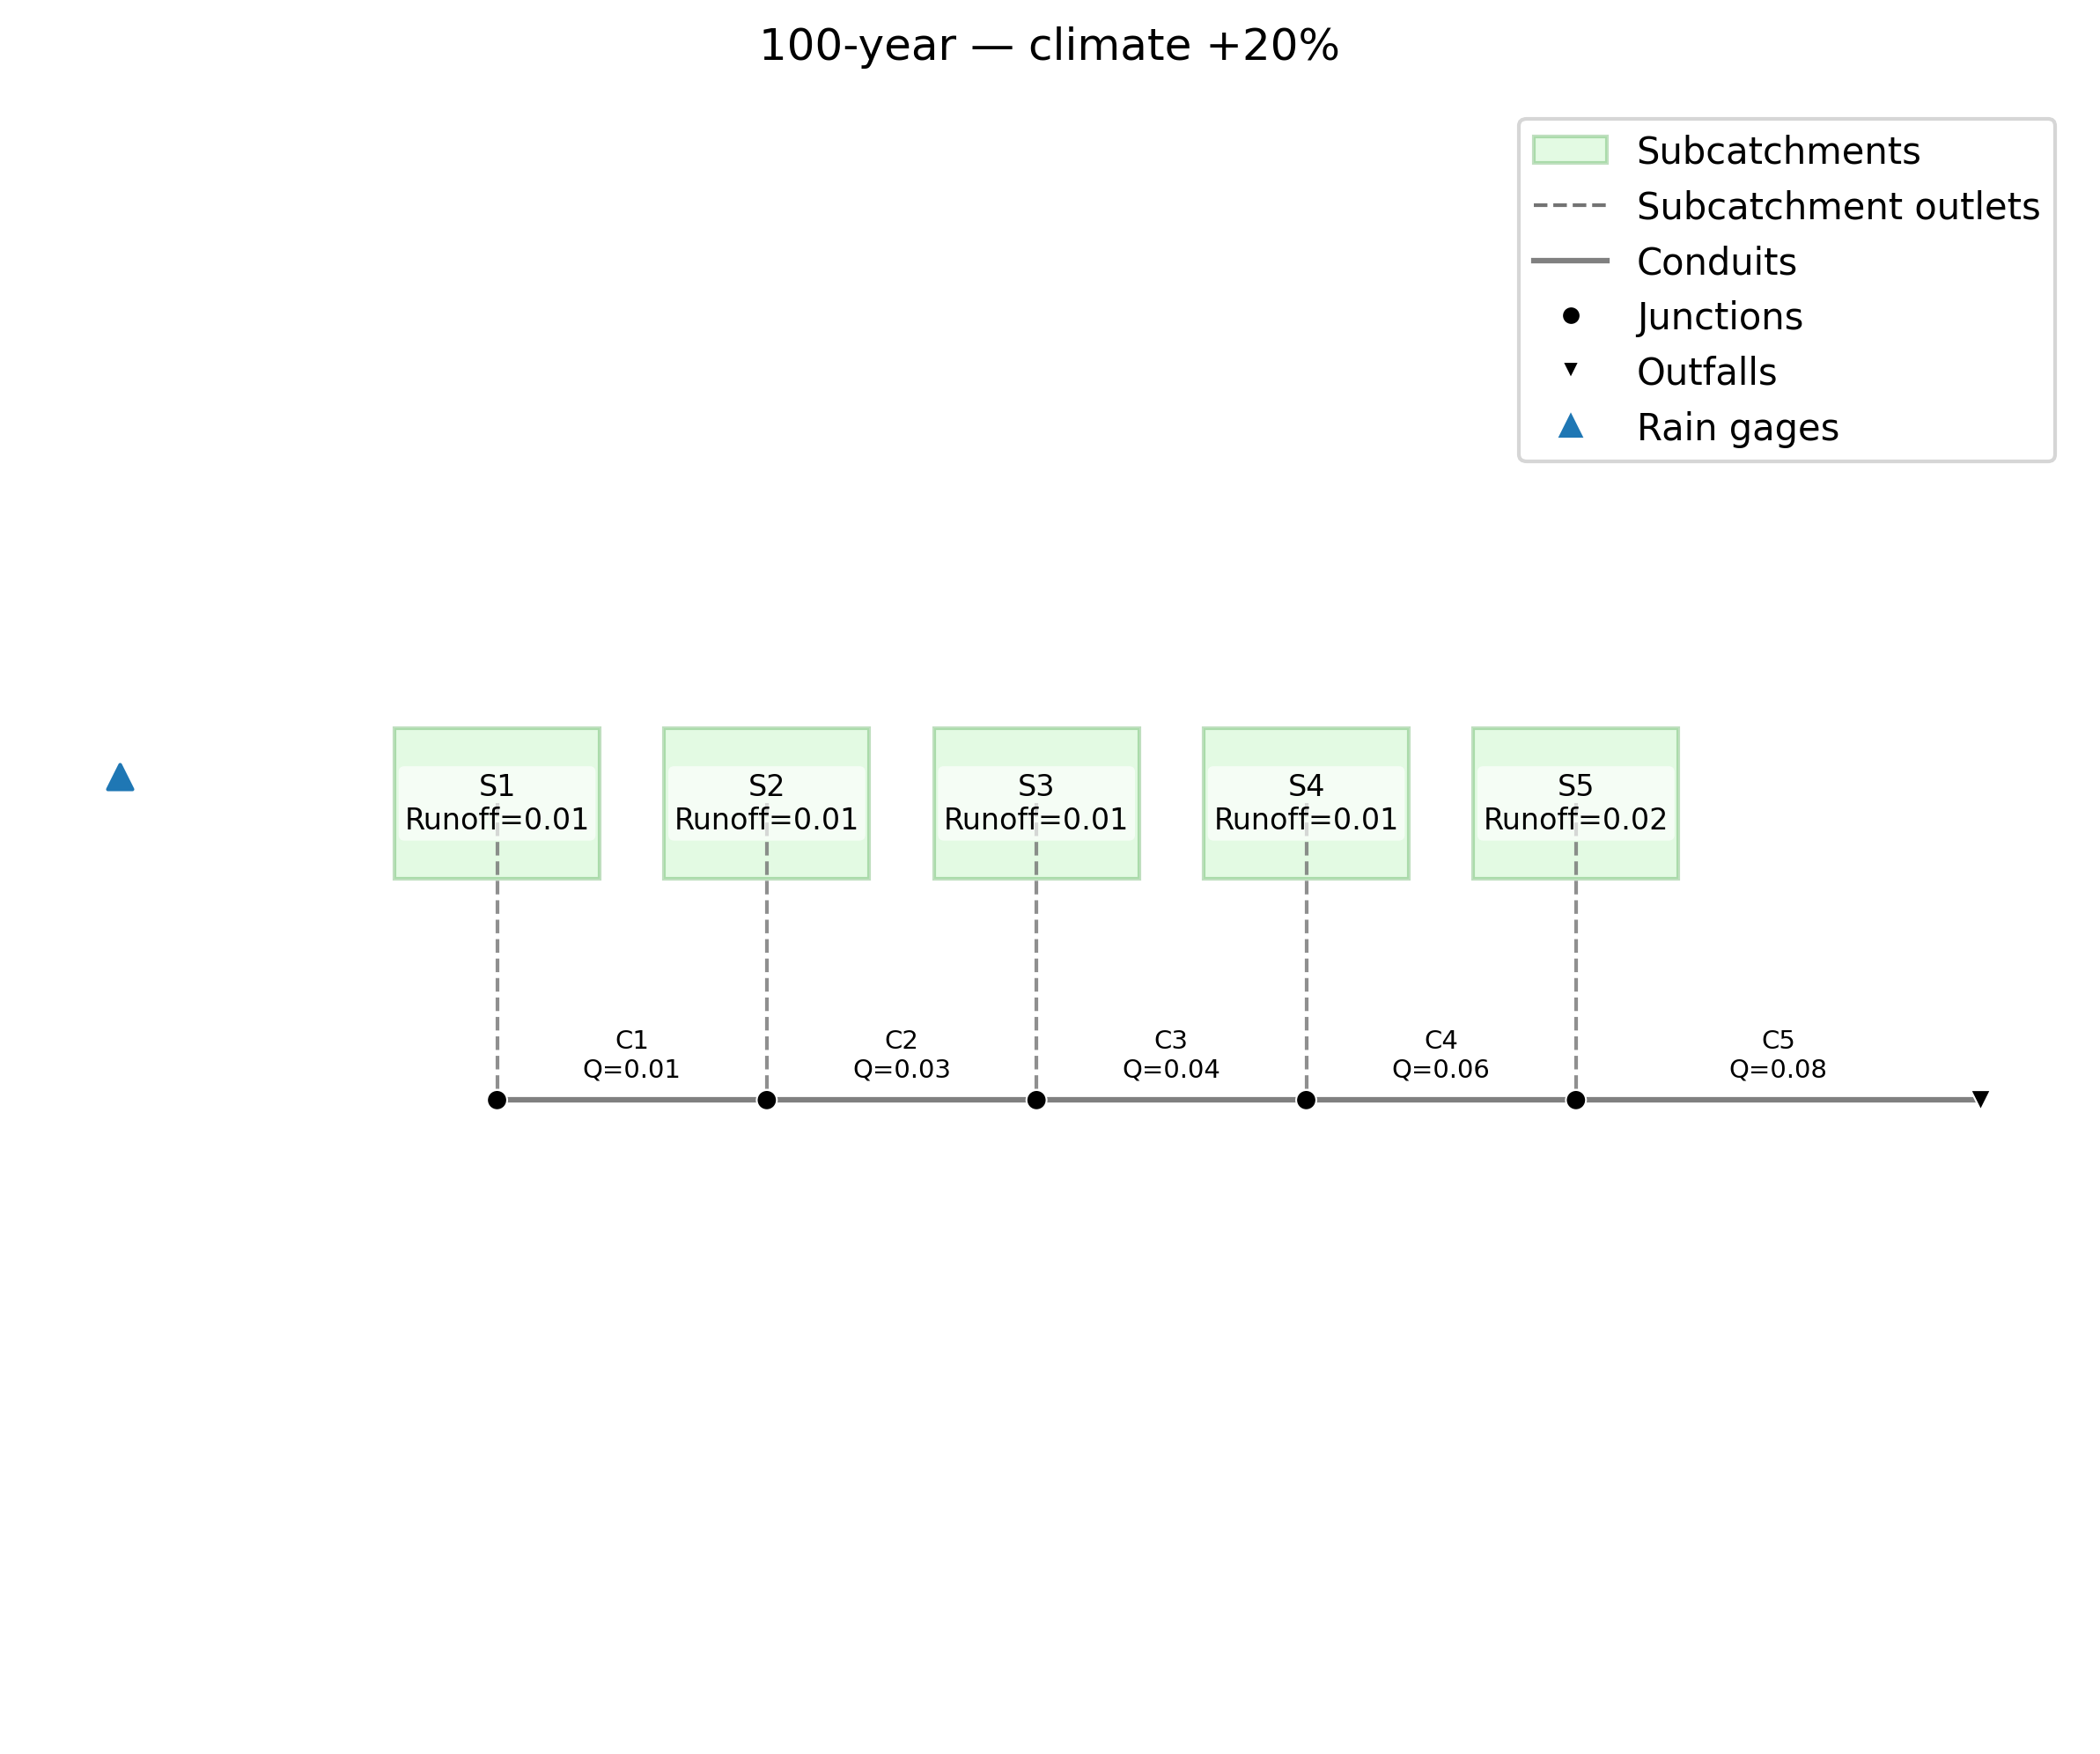

In [16]:
scenario_to_view = next(r for r in results if r["name"] == scenario_name("100-year", "climate +20%"))
scenario_to_view["model"].plot_layout(
    title=scenario_to_view["name"],
    annotation={
        "subcatchments": {"template": "{id}\nRunoff={runoff:.2f}", "fontsize": 8, "bbox": True},
        "conduits": {"template": "{id}\nQ={flow:.2f}", "fontsize": 7, "bbox": True, "rotation": "link"},
    },
)


## Export summary tables

The final cell saves the scenario metric tables to CSV files so they can be copied into reports or compared outside the notebook.


In [17]:
metrics.to_csv(OUTPUT_DIR / "rainfall_scenario_metrics.csv")
climate_effect.to_csv(OUTPUT_DIR / "climate_effect_metrics.csv")
subcatchment_peak.to_csv(OUTPUT_DIR / "subcatchment_peak_runoff.csv")
print(f"Saved outputs to: {OUTPUT_DIR.resolve()}")


Saved outputs to: C:\Users\Mohammadali\Documents\My_Codes\swmmx_dev\examples\output\rainfall_scenario_lab


## Suggested extensions

- Replace the illustrative rainfall depths with official local IDF depths.
- Add storm durations such as 1-hour, 3-hour, 12-hour, and 24-hour events.
- Compare alternative temporal distributions.
- Combine rainfall scenarios with LID scenarios from `examples/19_lid_scenario_comparison.ipynb`.
- Add flooding, surcharge, or link-capacity metrics if your model includes hydraulic routing details that make those outputs meaningful.
